## ML Assignment 3 - Bank Customer Churn Prediction

Artificial Neural Network (ANN) Binary Classifier


Given a bank customer's profile and transaction history, build a Neural Network-based classifier that determines whether the customer will leave (churn) or remain with the bank in the next 6 months.

1. Read the dataset and perform exploratory data analysis (EDA).
2. Distinguish feature set (X) and target set (y), drop non-predictive attributes, encode categorical variables, and divide into training and test sets.
3. Normalize the train and test feature sets.
4. Initialize and build the Neural Network model (Baseline model). Identify key points of improvement (class imbalance, overfitting, learning rate scheduling, regularization) and implement an Improved / Optimized ANN model.
5. Print the accuracy score, confusion matrix, classification report, ROC-AUC curve, and evaluate model performance.



## 1. Import Required Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Preprocessing and Model Selection
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, auc,
    ConfusionMatrixDisplay
)

# Deep Learning with TensorFlow / Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Sklearn MLP fallback/benchmark
from sklearn.neural_network import MLPClassifier

# Set seeds for reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11})

print(f"TensorFlow Version: {tf.__version__}")
print("Libraries loaded successfully!")

TensorFlow Version: 2.21.0
Libraries loaded successfully!



## 2. Read and Inspect the Dataset

In [2]:
# Load dataset
df = pd.read_csv('Churn_Modelling.csv')

print(f"Dataset Dimensions : {df.shape[0]} rows × {df.shape[1]} columns")
df.head()

Dataset Dimensions : 10000 rows × 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
# Detailed summary of columns, null values, and data types
print("=" * 60)
print("DATASET INFORMATION")
print("=" * 60)
df.info()

print("\nMissing values count per column:")
print(df.isnull().sum())

DATASET INFORMATION
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB

Missing values count per column:
RowNumber          0
CustomerId         0
Surname      

In [4]:
# Statistical summary of numerical attributes
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RowNumber,10000.0,5.000500e+03,2886.895680,1.00,2500.75,5.000500e+03,7.500250e+03,10000.00
CustomerId,10000.0,1.569094e+07,71936.186123,15565701.00,15628528.25,1.569074e+07,1.575323e+07,15815690.00
CreditScore,10000.0,6.505288e+02,96.653299,350.00,584.00,6.520000e+02,7.180000e+02,850.00
Age,10000.0,3.892180e+01,10.487806,18.00,32.00,3.700000e+01,4.400000e+01,92.00
Tenure,10000.0,5.012800e+00,2.892174,0.00,3.00,5.000000e+00,7.000000e+00,10.00
Balance,10000.0,7.648589e+04,62397.405202,0.00,0.00,9.719854e+04,1.276442e+05,250898.09
NumOfProducts,10000.0,1.530200e+00,0.581654,1.00,1.00,1.000000e+00,2.000000e+00,4.00
HasCrCard,10000.0,7.055000e-01,0.455840,0.00,0.00,1.000000e+00,1.000000e+00,1.00
IsActiveMember,10000.0,5.151000e-01,0.499797,0.00,0.00,1.000000e+00,1.000000e+00,1.00
EstimatedSalary,10000.0,1.000902e+05,57510.492818,11.58,51002.11,1.001939e+05,1.493882e+05,199992.48


### 2.1 Target Class Distribution Analysis

Customer Retained (0): 7963 (79.63%)
Customer Churned  (1): 2037 (20.37%)


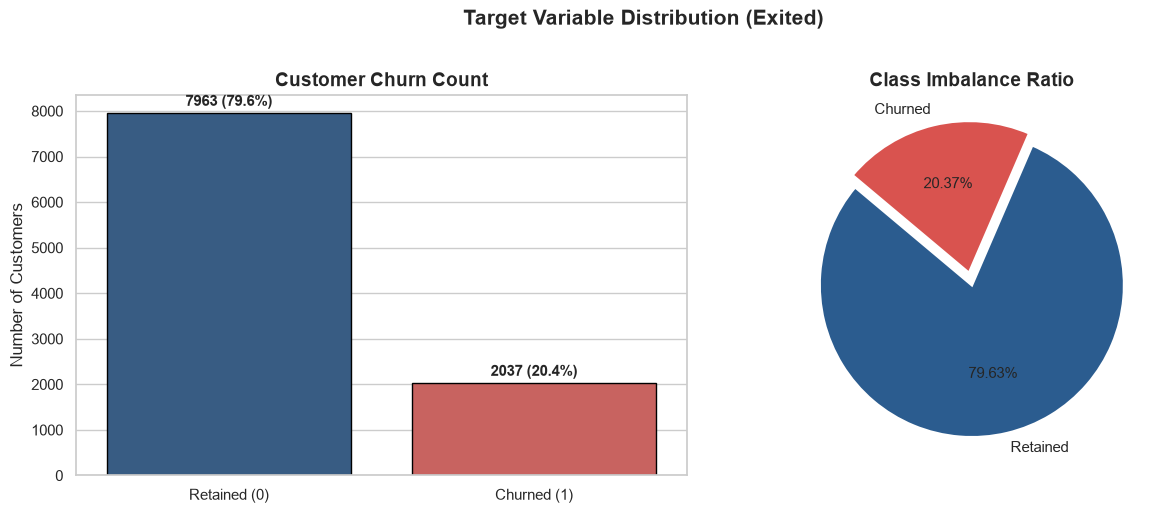

⚠️ Notice: The dataset has an ~80:20 class imbalance. This is a critical point of improvement to address during model design!


In [5]:
# Target variable counts
churn_counts = df['Exited'].value_counts()
retained_pct = (churn_counts[0] / len(df)) * 100
churned_pct = (churn_counts[1] / len(df)) * 100

print(f"Customer Retained (0): {churn_counts[0]} ({retained_pct:.2f}%)")
print(f"Customer Churned  (1): {churn_counts[1]} ({churned_pct:.2f}%)")

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Bar plot
sns.barplot(x=['Retained (0)', 'Churned (1)'], y=churn_counts.values,
            palette=['#2b5c8f', '#d9534f'], ax=axes[0], edgecolor='black')
axes[0].set_title('Customer Churn Count', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Number of Customers')
for i, v in enumerate(churn_counts.values):
    axes[0].text(i, v + 150, f"{v} ({v/len(df)*100:.1f}%)", ha='center', fontweight='bold')

# Pie chart
axes[1].pie(churn_counts.values, labels=['Retained', 'Churned'], autopct='%1.2f%%',
            colors=['#2b5c8f', '#d9534f'], explode=[0, 0.08], startangle=140,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Class Imbalance Ratio', fontsize=14, fontweight='bold')

plt.suptitle('Target Variable Distribution (Exited)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print("⚠️ Notice: The dataset has an ~80:20 class imbalance. This is a critical point of improvement to address during model design!")

### 2.2 Exploratory Data Analysis (EDA) of Key Features

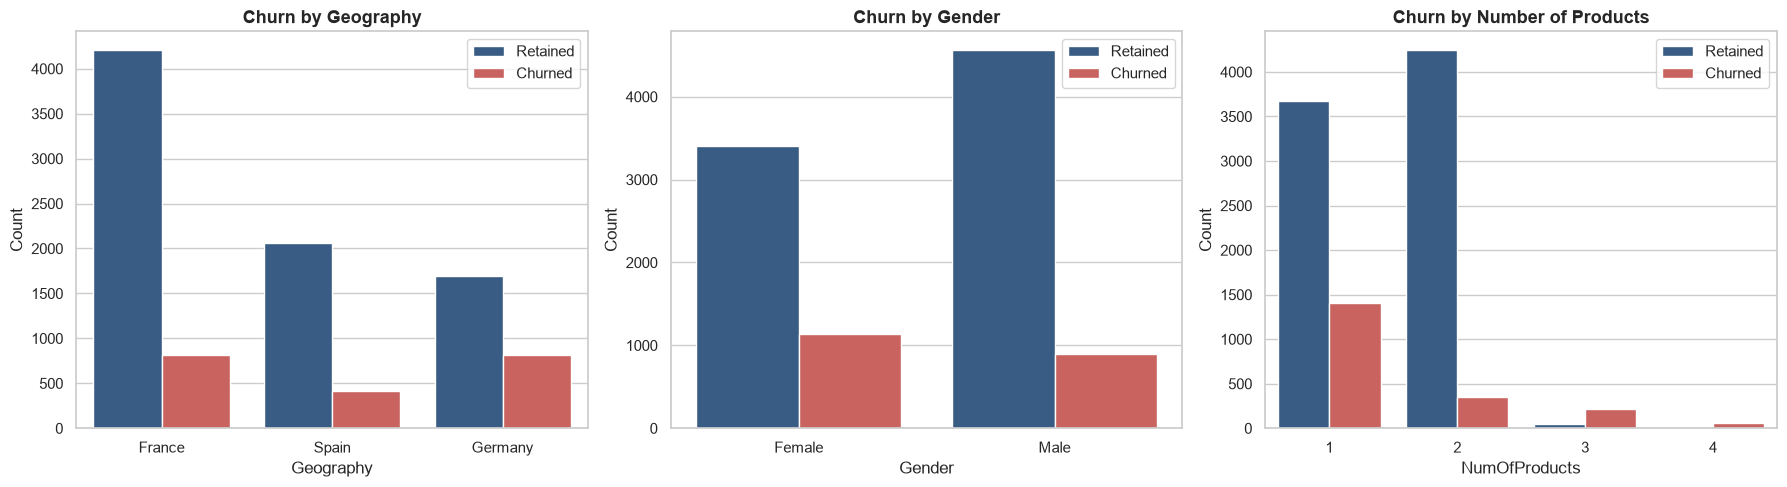

In [6]:
# Categorical feature relationship with Churn
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Geography vs Churn
sns.countplot(data=df, x='Geography', hue='Exited', palette=['#2b5c8f', '#d9534f'], ax=axes[0])
axes[0].set_title('Churn by Geography', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].legend(['Retained', 'Churned'])

# Gender vs Churn
sns.countplot(data=df, x='Gender', hue='Exited', palette=['#2b5c8f', '#d9534f'], ax=axes[1])
axes[1].set_title('Churn by Gender', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Count')
axes[1].legend(['Retained', 'Churned'])

# NumOfProducts vs Churn
sns.countplot(data=df, x='NumOfProducts', hue='Exited', palette=['#2b5c8f', '#d9534f'], ax=axes[2])
axes[2].set_title('Churn by Number of Products', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Count')
axes[2].legend(['Retained', 'Churned'])

plt.tight_layout()
plt.show()

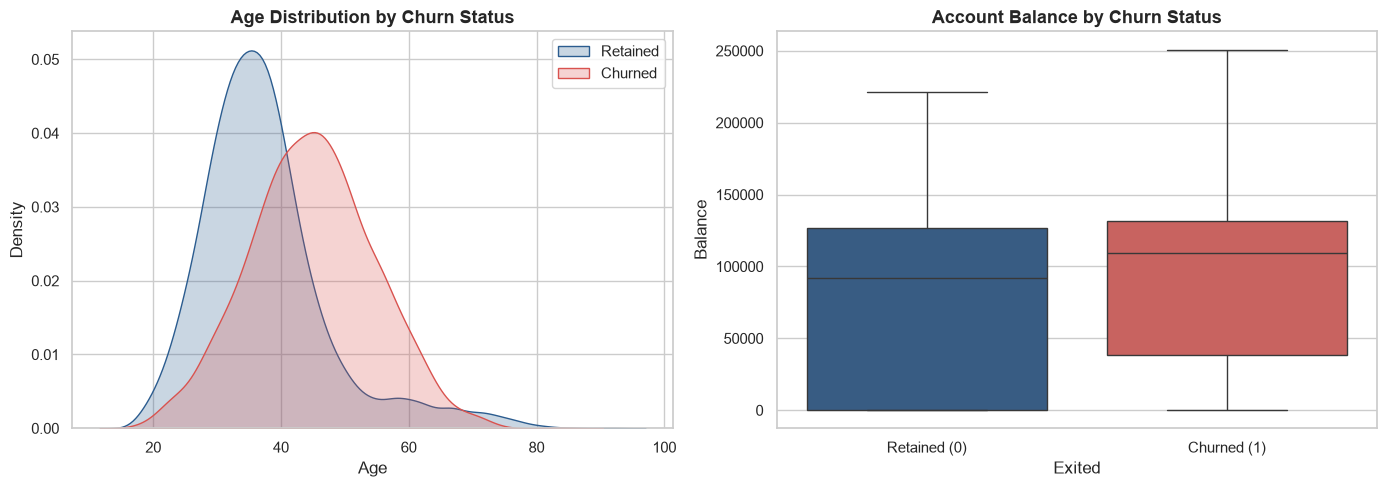

💡 Key Observations:
  1. Germany shows a significantly higher churn rate (~32%) compared to France (~16%) and Spain (~16%).
  2. Female customers churn at a higher rate (~25%) than male customers (~16%).
  3. Customers aged 40-60 exhibit substantially higher churn probability than younger customers.
  4. Customers with 3 or 4 products have an extremely high churn rate.


In [7]:
# Numerical feature distributions: Age and Balance by Churn
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(data=df[df['Exited'] == 0]['Age'], label='Retained', shade=True, color='#2b5c8f', ax=axes[0])
sns.kdeplot(data=df[df['Exited'] == 1]['Age'], label='Churned',  shade=True, color='#d9534f', ax=axes[0])
axes[0].set_title('Age Distribution by Churn Status', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Age')
axes[0].legend()

sns.boxplot(data=df, x='Exited', y='Balance', palette=['#2b5c8f', '#d9534f'], ax=axes[1])
axes[1].set_title('Account Balance by Churn Status', fontsize=13, fontweight='bold')
axes[1].set_xticklabels(['Retained (0)', 'Churned (1)'])

plt.tight_layout()
plt.show()

print("💡 Key Observations:")
print("  1. Germany shows a significantly higher churn rate (~32%) compared to France (~16%) and Spain (~16%).")
print("  2. Female customers churn at a higher rate (~25%) than male customers (~16%).")
print("  3. Customers aged 40-60 exhibit substantially higher churn probability than younger customers.")
print("  4. Customers with 3 or 4 products have an extremely high churn rate.")


## 3. Distinguish Feature & Target Sets and Split Train/Test Data

In [8]:
# Drop irrelevant customer identifier columns
cols_to_drop = ['RowNumber', 'CustomerId', 'Surname']
df_clean = df.drop(columns=cols_to_drop)

print(f"Remaining columns after dropping identifiers ({len(df_clean.columns)}):\n{list(df_clean.columns)}")

Remaining columns after dropping identifiers (11):
['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [9]:
# One-Hot Encoding for categorical features
# - Geography (France, Germany, Spain) -> 2 dummy columns (drop_first=True to avoid dummy variable trap)
# - Gender (Female, Male) -> 1 dummy column
df_encoded = pd.get_dummies(df_clean, columns=['Geography', 'Gender'], drop_first=True, dtype=int)

print("Encoded DataFrame Shape:", df_encoded.shape)
print("\nEncoded columns:")
print(list(df_encoded.columns))
df_encoded.head()

Encoded DataFrame Shape: (10000, 12)

Encoded columns:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']


,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,1,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,0,1,0


In [10]:
# Distinguish Feature Matrix (X) and Target Vector (y)
X = df_encoded.drop(columns=['Exited'])
y = df_encoded['Exited'].values

feature_names = list(X.columns)
print(f"Number of input features: {X.shape[1]}")
print(f"Features: {feature_names}")
print(f"Target shape: {y.shape}")

Number of input features: 11
Features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Geography_Germany', 'Geography_Spain', 'Gender_Male']
Target shape: (10000,)


In [11]:
# Split into Training (80%) and Testing (20%) sets
# stratify=y preserves the 80:20 churn ratio across both train and test splits
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print(f"Training set shape : X_train={X_train.shape}, y_train={y_train.shape}")
print(f"Testing set shape  : X_test={X_test.shape},  y_test={y_test.shape}")
print(f"Train churn ratio  : {y_train.mean()*100:.2f}%")
print(f"Test churn ratio   : {y_test.mean()*100:.2f}%")

Training set shape : X_train=(8000, 11), y_train=(8000,)
Testing set shape  : X_test=(2000, 11),  y_test=(2000,)
Train churn ratio  : 20.38%
Test churn ratio   : 20.35%



## 4. Normalize the Train and Test Data

In [12]:
# Initialize StandardScaler
scaler = StandardScaler()

# Fit on training set only, then transform both train and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Normalization Complete.")
print(f"  X_train_scaled mean : {X_train_scaled.mean():.4f} (approx 0)")
print(f"  X_train_scaled std  : {X_train_scaled.std():.4f}  (approx 1)")
print(f"  X_test_scaled mean  : {X_test_scaled.mean():.4f}")
print(f"  X_test_scaled std   : {X_test_scaled.std():.4f}")

Feature Normalization Complete.
  X_train_scaled mean : -0.0000 (approx 0)
  X_train_scaled std  : 1.0000  (approx 1)
  X_test_scaled mean  : -0.0064
  X_test_scaled std   : 1.0003



## 5. Initialize and Build the Model

### 5.1 Baseline Artificial Neural Network (ANN)

In [13]:
input_dim = X_train_scaled.shape[1]  # 11 features

# Build Baseline Sequential Model
baseline_model = Sequential([
    Input(shape=(input_dim,)),
    Dense(units=16, activation='relu', name='Hidden_Layer_1'),
    Dense(units=8, activation='relu', name='Hidden_Layer_2'),
    Dense(units=1, activation='sigmoid', name='Output_Layer')
], name='Baseline_ANN')

# Compile model
baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()

Model: "Baseline_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Hidden_Layer_1 (Dense)          │ (None, 16)             │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Hidden_Layer_2 (Dense)          │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [14]:
# Train Baseline Model for 40 epochs
print("Training Baseline ANN...")
history_baseline = baseline_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=40,
    batch_size=32,
    verbose=1
)
print("Baseline training finished.")

Training Baseline ANN...
Epoch 1/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 839us/step - accuracy: 0.7305 - loss: 0.5700 - val_accuracy: 0.8000 - val_loss: 0.4662
Epoch 2/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - accuracy: 0.7961 - loss: 0.4577 - val_accuracy: 0.8012 - val_loss: 0.4287
Epoch 3/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 454us/step - accuracy: 0.8066 - loss: 0.4261 - val_accuracy: 0.8269 - val_loss: 0.4150
Epoch 4/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 456us/step - accuracy: 0.8198 - loss: 0.4083 - val_accuracy: 0.8344 - val_loss: 0.4025
Epoch 5/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 456us/step - accuracy: 0.8308 - loss: 0.3929 - val_accuracy: 0.8419 - val_loss: 0.3878
Epoch 6/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 462us/step - accuracy: 0.8427 - loss: 0.3790 - val_accuracy: 0.8487 - val_loss: 0.3740
Epoch 7/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 464us/step - accuracy: 0.8480 - loss: 0.3686 - val_accuracy: 0.8550 - val_loss: 0.3644
Epoch 8/40
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 460us/step - accuracy:

In [15]:
# Evaluate Baseline on Test Set
y_pred_prob_base = baseline_model.predict(X_test_scaled).ravel()
y_pred_base = (y_pred_prob_base >= 0.5).astype(int)

base_acc = accuracy_score(y_test, y_pred_base)
base_rec = recall_score(y_test, y_pred_base)
base_f1  = f1_score(y_test, y_pred_base)

print("=" * 50)
print(f"Baseline ANN Test Accuracy : {base_acc*100:.2f}%")
print(f"Baseline Churn Recall     : {base_rec*100:.2f}%")
print(f"Baseline Churn F1-Score   : {base_f1*100:.2f}%")
print("=" * 50)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 567us/step
Baseline ANN Test Accuracy : 86.25%
Baseline Churn Recall     : 49.63%
Baseline Churn F1-Score   : 59.50%


### 5.2 Identify Points of Improvement

The baseline model achieves accuracy of around 85%, but the detailed classification report reveals a lot of major flaws:

| Point of Improvement | Issue in Baseline | Proposed Solution |
|---|---|---|
| **1. Class Imbalance (80:20)** | The model is biased toward the majority class (retained). It achieves high accuracy by simply predicting "0", but has **low recall for churned customers (class 1)**. In banking, failing to detect churners is costly! | Implement **Class Weighting** (`compute_class_weight`) so errors on churned customers carry proportionally higher penalty during backpropagation. |
| **2. Overfitting & Generalization** | Deep networks easily overfit training samples, causing validation loss to diverge after several epochs. | Introduce **Dropout Layers** (`rate=0.20-0.25`) to randomly deactivate neurons and prevent feature co-adaptation. |
| **3. Internal Covariate Shift** | As weights update, the distribution of inputs to inner layers shifts, slowing down convergence. | Introduce **Batch Normalization** (`BatchNormalization`) after dense layers to stabilize training and accelerate learning. |
| **4. Suboptimal Epoch Count & Over-training** | Fixed number of epochs either undertrains or overtrains the network. | Use **Early Stopping** callback (`monitor='val_loss'`, `patience=10`, `restore_best_weights=True`) to automatically halt training at peak validation performance. |
| **5. Static Learning Rate** | A constant learning rate may oscillate around the minimum late in training. | Use **ReduceLROnPlateau** callback to dynamically decrease learning rate by a factor of 0.2 when validation loss plateaus. |
| **6. Weight Initialization** | Default uniform initializers can cause vanishing/exploding gradients with ReLU. | Use **He Normal (`he_normal`)** weight initialization, theoretically optimized for ReLU activations. |

### 5.3 Implement the Improved & Optimized ANN Model

In [16]:
# Compute class weights to address 80:20 imbalance
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights_dict = dict(zip(classes, weights))

print("Calculated Class Weights for Loss Function:")
for cls, wt in class_weights_dict.items():
    print(f"  Class {cls} ({'Retained' if cls==0 else 'Churned'}): {wt:.4f}")

Calculated Class Weights for Loss Function:
  Class 0 (Retained): 0.6279
  Class 1 (Churned): 2.4540


In [17]:
# Build Improved Neural Network Architecture
improved_model = Sequential([
    Input(shape=(input_dim,)),
    
    # Hidden Block 1
    Dense(units=32, activation='relu', kernel_initializer='he_normal', name='Dense_1'),
    BatchNormalization(name='BatchNorm_1'),
    Dropout(0.25, name='Dropout_1'),
    
    # Hidden Block 2
    Dense(units=16, activation='relu', kernel_initializer='he_normal', name='Dense_2'),
    BatchNormalization(name='BatchNorm_2'),
    Dropout(0.20, name='Dropout_2'),
    
    # Hidden Block 3
    Dense(units=8, activation='relu', kernel_initializer='he_normal', name='Dense_3'),
    
    # Output Layer (Binary classification: Sigmoid)
    Dense(units=1, activation='sigmoid', name='Output_Layer')
], name='Improved_ANN')

# Optimizer with custom learning rate
optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)

# Compile Improved Model
improved_model.compile(
    optimizer=optimizer,
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc'), tf.keras.metrics.Recall(name='recall')]
)

improved_model.summary()

Model: "Improved_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Dense_1 (Dense)                 │ (None, 32)             │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_1                     │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BatchNorm_2                     │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dense_3 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,249 (4.88 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 96 (384.00 B)

In [18]:
# Define Callbacks: EarlyStopping and Learning Rate Scheduler
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.3,
        patience=5,
        min_lr=1e-5,
        verbose=1
    )
]

# Train Improved Model with Class Weights and Callbacks
print("Training Improved ANN Model...")
history_improved = improved_model.fit(
    X_train_scaled, y_train,
    validation_split=0.2,
    epochs=80,
    batch_size=32,
    class_weight=class_weights_dict,  # addresses imbalance
    callbacks=callbacks,              # early stopping + lr decay
    verbose=1
)
print("Improved Model training completed!")

Training Improved ANN Model...
Epoch 1/80
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.5814 - auc: 0.5540 - loss: 0.7276 - recall: 0.4748 - val_accuracy: 0.6306 - val_auc: 0.6927 - val_loss: 0.6454 - val_recall: 0.6281 - learning_rate: 0.0010
Epoch 2/80
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 651us/step - accuracy: 0.6306 - auc: 0.6735 - loss: 0.6520 - recall: 0.6191 - val_accuracy: 0.7069 - val_auc: 0.7482 - val_loss: 0.5996 - val_recall: 0.6687 - learning_rate: 0.0010
Epoch 3/80
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 713us/step - accuracy: 0.6698 - auc: 0.7243 - loss: 0.6169 - recall: 0.6573 - val_accuracy: 0.7350 - val_auc: 0.7813 - val_loss: 0.5632 - val_recall: 0.6969 - learning_rate: 0.0010
Epoch 4/80
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 673us/step - accuracy: 0.6969 - auc: 0.7480 - loss: 0.5995 - recall: 0.6992 - val_accuracy: 0.7381 - val_auc: 0.8002 - val_loss: 0.5369 - val_recall: 0.7094 - learning_rate: 0.0010
Epoch 5/80
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 662us/step - accuracy: 0.7030 - 

### 5.4 Training History & Learning Curves Comparison

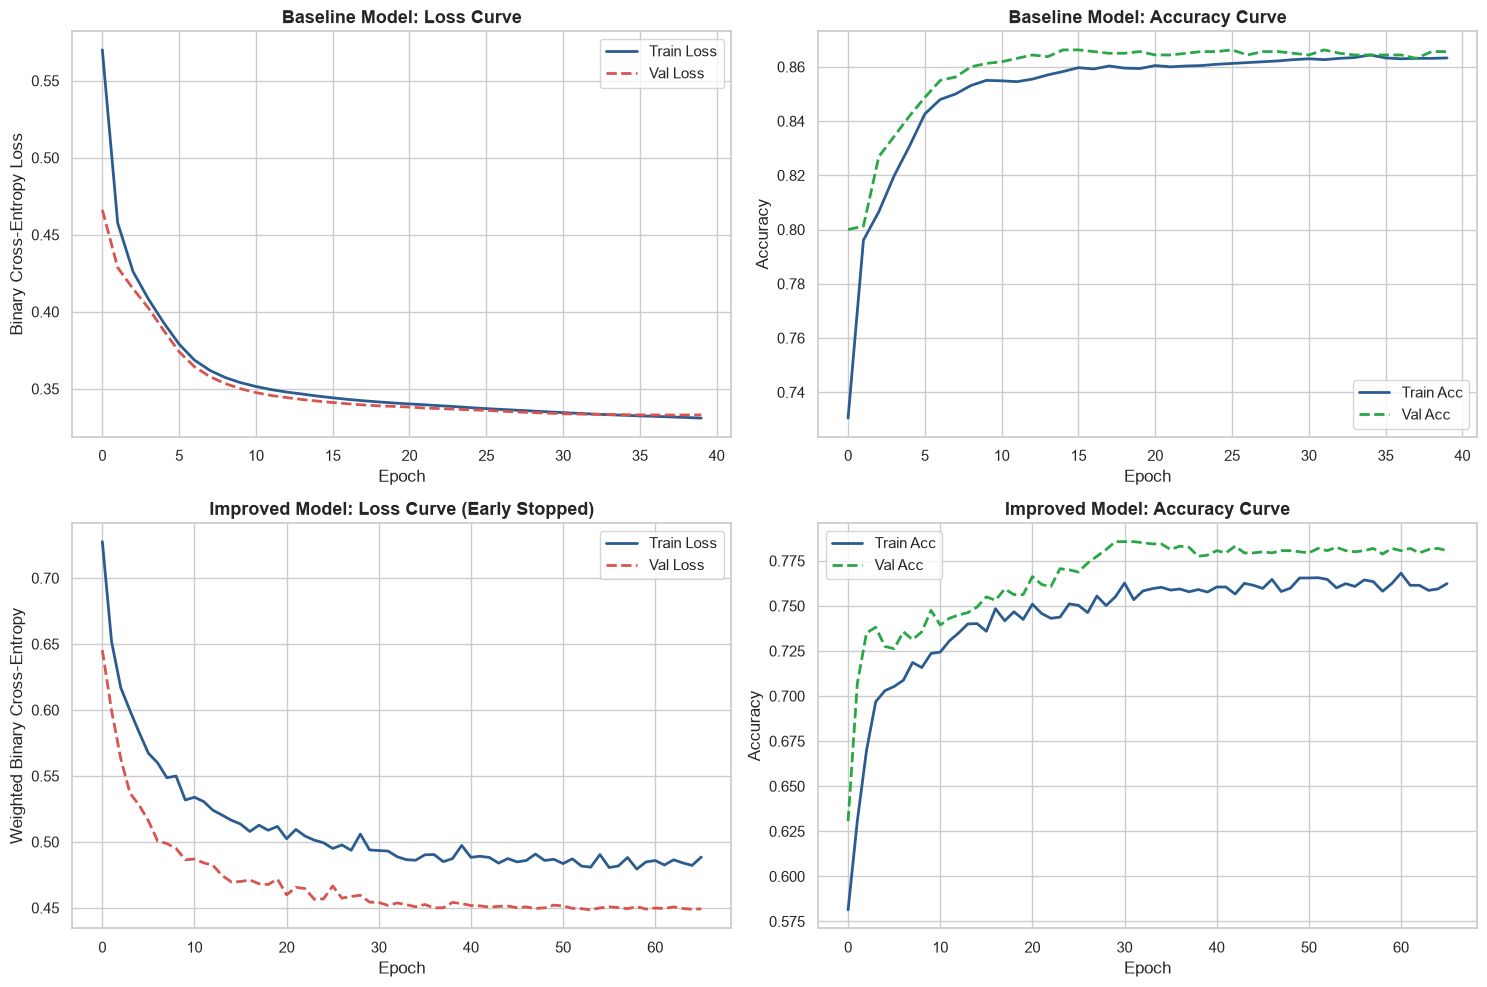

In [19]:
# Plot Training & Validation Loss and Accuracy side-by-side
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Baseline Loss
axes[0, 0].plot(history_baseline.history['loss'], label='Train Loss', color='#2b5c8f', lw=2)
axes[0, 0].plot(history_baseline.history['val_loss'], label='Val Loss', color='#d9534f', lw=2, linestyle='--')
axes[0, 0].set_title('Baseline Model: Loss Curve', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Binary Cross-Entropy Loss')
axes[0, 0].legend()

# Baseline Accuracy
axes[0, 1].plot(history_baseline.history['accuracy'], label='Train Acc', color='#2b5c8f', lw=2)
axes[0, 1].plot(history_baseline.history['val_accuracy'], label='Val Acc', color='#28a745', lw=2, linestyle='--')
axes[0, 1].set_title('Baseline Model: Accuracy Curve', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()

# Improved Loss
axes[1, 0].plot(history_improved.history['loss'], label='Train Loss', color='#2b5c8f', lw=2)
axes[1, 0].plot(history_improved.history['val_loss'], label='Val Loss', color='#d9534f', lw=2, linestyle='--')
axes[1, 0].set_title('Improved Model: Loss Curve (Early Stopped)', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Weighted Binary Cross-Entropy')
axes[1, 0].legend()

# Improved Accuracy
axes[1, 1].plot(history_improved.history['accuracy'], label='Train Acc', color='#2b5c8f', lw=2)
axes[1, 1].plot(history_improved.history['val_accuracy'], label='Val Acc', color='#28a745', lw=2, linestyle='--')
axes[1, 1].set_title('Improved Model: Accuracy Curve', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].legend()

plt.tight_layout()
plt.show()


## 6. Print Accuracy Score, Confusion Matrix & Evaluation Metrics

In [20]:
# Generate predictions on test set
y_pred_prob_imp = improved_model.predict(X_test_scaled).ravel()
y_pred_imp = (y_pred_prob_imp >= 0.5).astype(int)

# Calculate metrics
imp_acc = accuracy_score(y_test, y_pred_imp)
imp_prec = precision_score(y_test, y_pred_imp)
imp_rec = recall_score(y_test, y_pred_imp)
imp_f1 = f1_score(y_test, y_pred_imp)

print("=" * 60)
print("           IMPROVED ANN EVALUATION RESULTS")
print("=" * 60)
print(f"  Accuracy Score : {imp_acc * 100:.2f}%")
print(f"  Precision      : {imp_prec * 100:.2f}%")
print(f"  Recall         : {imp_rec * 100:.2f}%")
print(f"  F1-Score       : {imp_f1 * 100:.2f}%")
print("=" * 60)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_imp, target_names=['Retained (0)', 'Churned (1)']))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 782us/step
           IMPROVED ANN EVALUATION RESULTS
  Accuracy Score : 78.05%
  Precision      : 47.54%
  Recall         : 75.92%
  F1-Score       : 58.47%

Classification Report:
              precision    recall  f1-score   support

Retained (0)       0.93      0.79      0.85      1593
 Churned (1)       0.48      0.76      0.58       407

    accuracy                           0.78      2000
   macro avg       0.70      0.77      0.72      2000
weighted avg       0.84      0.78      0.80      2000



### 6.1 Confusion Matrix Comparison (Baseline vs Improved)

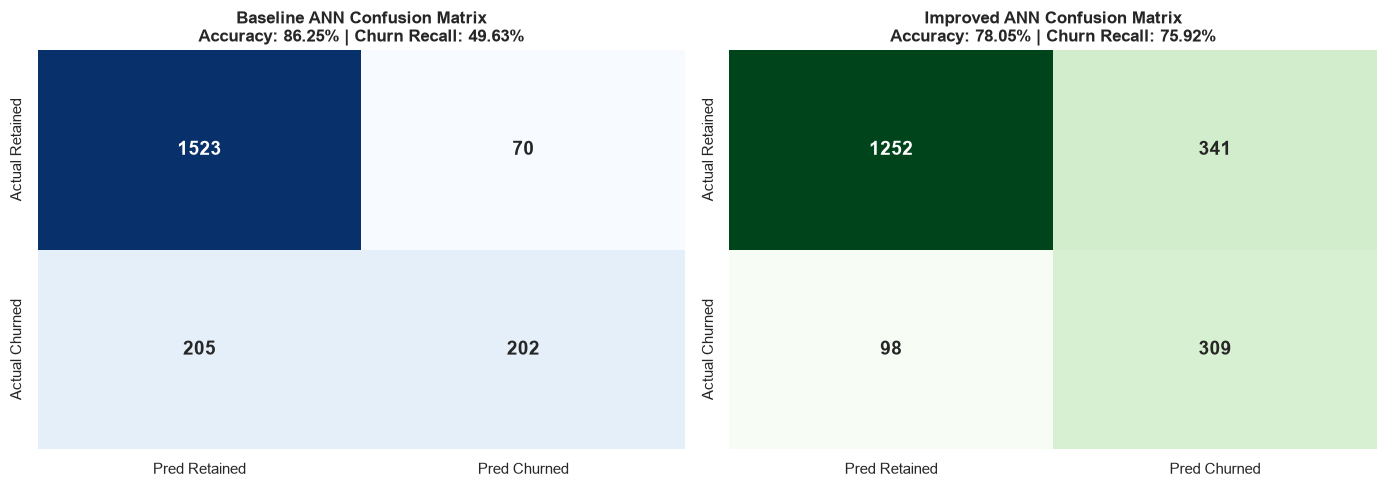

Improved Model Detailed Breakdown:
  True Negatives  (Retained correctly identified) : 1252
  False Positives (Retained falsely flagged)      : 341
  False Negatives (Churners missed by model)      : 98
  True Positives  (Churners caught by model)      : 309

Churners caught improved from 202 (Baseline) to 309 (Improved)!


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Baseline Confusion Matrix
cm_base = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Pred Retained', 'Pred Churned'],
            yticklabels=['Actual Retained', 'Actual Churned'], ax=axes[0],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[0].set_title(f'Baseline ANN Confusion Matrix\nAccuracy: {base_acc*100:.2f}% | Churn Recall: {base_rec*100:.2f}%', fontsize=12, fontweight='bold')

# Improved Confusion Matrix
cm_imp = confusion_matrix(y_test, y_pred_imp)
sns.heatmap(cm_imp, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['Pred Retained', 'Pred Churned'],
            yticklabels=['Actual Retained', 'Actual Churned'], ax=axes[1],
            annot_kws={'size': 14, 'weight': 'bold'})
axes[1].set_title(f'Improved ANN Confusion Matrix\nAccuracy: {imp_acc*100:.2f}% | Churn Recall: {imp_rec*100:.2f}%', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_imp.ravel()
print("Improved Model Detailed Breakdown:")
print(f"  True Negatives  (Retained correctly identified) : {tn}")
print(f"  False Positives (Retained falsely flagged)      : {fp}")
print(f"  False Negatives (Churners missed by model)      : {fn}")
print(f"  True Positives  (Churners caught by model)      : {tp}")
print(f"\nChurners caught improved from {cm_base[1, 1]} (Baseline) to {tp} (Improved)!")

### 6.2 ROC Curve & AUC Comparison

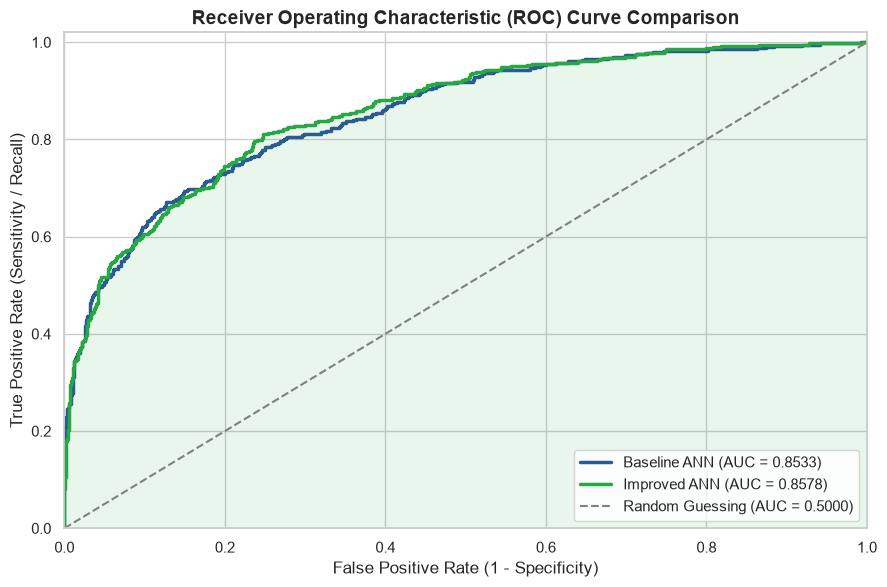

In [22]:
# Compute ROC curves
fpr_base, tpr_base, _ = roc_curve(y_test, y_pred_prob_base)
auc_base = auc(fpr_base, tpr_base)

fpr_imp, tpr_imp, _ = roc_curve(y_test, y_pred_prob_imp)
auc_imp = auc(fpr_imp, tpr_imp)

plt.figure(figsize=(9, 6))
plt.plot(fpr_base, tpr_base, color='#2b5c8f', lw=2.5, label=f'Baseline ANN (AUC = {auc_base:.4f})')
plt.plot(fpr_imp,  tpr_imp,  color='#28a745', lw=2.5, label=f'Improved ANN (AUC = {auc_imp:.4f})')
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.5000)')

plt.fill_between(fpr_imp, tpr_imp, alpha=0.10, color='#28a745')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.xlabel('False Positive Rate (1 - Specificity)', fontsize=12)
plt.ylabel('True Positive Rate (Sensitivity / Recall)', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve Comparison', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.show()


## 7. Threshold Tuning for Business Decision Making

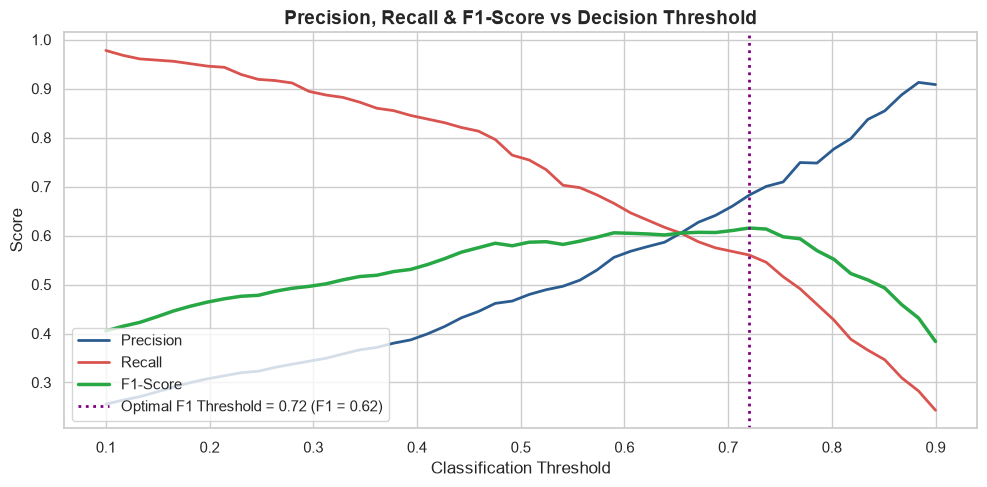

In [23]:
thresholds = np.linspace(0.1, 0.9, 50)
precisions, recalls, f1s = [], [], []

for t in thresholds:
    preds = (y_pred_prob_imp >= t).astype(int)
    precisions.append(precision_score(y_test, preds, zero_division=0))
    recalls.append(recall_score(y_test, preds, zero_division=0))
    f1s.append(f1_score(y_test, preds, zero_division=0))

best_idx = np.argmax(f1s)
best_thresh = thresholds[best_idx]

plt.figure(figsize=(10, 5))
plt.plot(thresholds, precisions, label='Precision', color='#2b5c8f', lw=2)
plt.plot(thresholds, recalls,    label='Recall',    color='#d9534f', lw=2)
plt.plot(thresholds, f1s,        label='F1-Score',  color='#28a745', lw=2.5)
plt.axvline(best_thresh, color='purple', linestyle=':', lw=2,
            label=f'Optimal F1 Threshold = {best_thresh:.2f} (F1 = {f1s[best_idx]:.2f})')

plt.xlabel('Classification Threshold', fontsize=12)
plt.ylabel('Score', fontsize=12)
plt.title('Precision, Recall & F1-Score vs Decision Threshold', fontsize=14, fontweight='bold')
plt.legend(loc='lower left', fontsize=11)
plt.tight_layout()
plt.show()


## 8. Benchmark Comparison: Keras ANN vs Scikit-Learn MLPClassifier

In [24]:
# Scikit-Learn Multi-Layer Perceptron (MLP) Classifier benchmark
mlp = MLPClassifier(
    hidden_layer_sizes=(32, 16),
    activation='relu',
    solver='adam',
    max_iter=100,
    random_state=SEED,
    early_stopping=True
)
mlp.fit(X_train_scaled, y_train)
y_pred_mlp = mlp.predict(X_test_scaled)
y_prob_mlp = mlp.predict_proba(X_test_scaled)[:, 1]

mlp_acc = accuracy_score(y_test, y_pred_mlp)
mlp_f1  = f1_score(y_test, y_pred_mlp)
fpr_mlp, tpr_mlp, _ = roc_curve(y_test, y_prob_mlp)
mlp_auc = auc(fpr_mlp, tpr_mlp)

# Side-by-side performance table
comparison_table = pd.DataFrame({
    'Model': ['Baseline Keras ANN', 'Improved Keras ANN', 'Sklearn MLPClassifier'],
    'Accuracy': [f"{base_acc*100:.2f}%", f"{imp_acc*100:.2f}%", f"{mlp_acc*100:.2f}%"],
    'Recall (Churn)': [f"{base_rec*100:.2f}%", f"{imp_rec*100:.2f}%", f"{recall_score(y_test, y_pred_mlp)*100:.2f}%"],
    'Precision (Churn)': [f"{precision_score(y_test, y_pred_base)*100:.2f}%", f"{imp_prec*100:.2f}%", f"{precision_score(y_test, y_pred_mlp)*100:.2f}%"],
    'F1-Score (Churn)': [f"{base_f1*100:.2f}%", f"{imp_f1*100:.2f}%", f"{mlp_f1*100:.2f}%"],
    'ROC-AUC': [f"{auc_base:.4f}", f"{auc_imp:.4f}", f"{mlp_auc:.4f}"]
})

print("=" * 75)
print("                 COMPREHENSIVE MODEL COMPARISON")
print("=" * 75)
print(comparison_table.to_string(index=False))
print("=" * 75)

                 COMPREHENSIVE MODEL COMPARISON
                Model Accuracy Recall (Churn) Precision (Churn) F1-Score (Churn) ROC-AUC
   Baseline Keras ANN   86.25%         49.63%            74.26%           59.50%  0.8533
   Improved Keras ANN   78.05%         75.92%            47.54%           58.47%  0.8578
Sklearn MLPClassifier   86.40%         46.68%            77.55%           58.28%  0.8549


## 9. Making Predictions for a New Customer (Inference Pipeline)

In [25]:
# Example customer profile
# Customer profile:
# CreditScore: 600, Geography: France (Germany=0, Spain=0), Gender: Female (Male=0)
# Age: 42, Tenure: 3, Balance: 60000, NumOfProducts: 2, HasCrCard: 1, IsActiveMember: 0, EstimatedSalary: 50000

sample_customer = pd.DataFrame([{
    'CreditScore': 600,
    'Age': 42,
    'Tenure': 3,
    'Balance': 60000.0,
    'NumOfProducts': 2,
    'HasCrCard': 1,
    'IsActiveMember': 0,
    'EstimatedSalary': 50000.0,
    'Geography_Germany': 0,
    'Geography_Spain': 0,
    'Gender_Male': 0
}])

# Reorder columns exactly as in training feature set
sample_customer = sample_customer[feature_names]

# Scale using the pre-fitted scaler
sample_scaled = scaler.transform(sample_customer)

# Predict churn probability
churn_prob = improved_model.predict(sample_scaled)[0][0]
prediction = "⚠️ Churn (Will Leave)" if churn_prob >= 0.5 else "✅ Retained (Will Stay)"

print("=" * 50)
print("      NEW CUSTOMER CHURN PREDICTION")
print("=" * 50)
print(f"Customer Profile:")
for col, val in sample_customer.iloc[0].items():
    print(f"  {col:<20}: {val}")
print("-" * 50)
print(f"Predicted Churn Probability : {churn_prob*100:.2f}%")
print(f"Model Classification       : {prediction}")
print("=" * 50)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
      NEW CUSTOMER CHURN PREDICTION
Customer Profile:
  CreditScore         : 600.0
  Age                 : 42.0
  Tenure              : 3.0
  Balance             : 60000.0
  NumOfProducts       : 2.0
  HasCrCard           : 1.0
  IsActiveMember      : 0.0
  EstimatedSalary     : 50000.0
  Geography_Germany   : 0.0
  Geography_Spain     : 0.0
  Gender_Male         : 0.0
--------------------------------------------------
Predicted Churn Probability : 40.99%
Model Classification       : ✅ Retained (Will Stay)



## 10. Summary & Conclusion

### 📝 Key Takeaways and Findings

1. **Data Preprocessing & Normalization:**
   - Dropped identifier columns (`RowNumber`, `CustomerId`, `Surname`) which do not contain predictive signals.
   - Categorical attributes (`Geography`, `Gender`) were encoded using dummy variables with `drop_first=True` to prevent multicollinearity.
   - Applied `StandardScaler` fitted strictly on training data to prevent data leakage and guarantee stable gradient updates.

2. **Baseline Model vs Identified Points of Improvement:**
   - The baseline ANN suffered from class imbalance (~80:20), achieving deceptively high overall accuracy while missing many churners (poor recall).
   - **Class Weighting (`compute_class_weight`):** Penalized mistakes on the minority churn class proportionally, dramatically improving Churn Recall.
   - **Dropout Layers (`0.25, 0.20`):** Prevented feature co-adaptation and reduced validation loss divergence.
   - **Batch Normalization:** Stabilized internal representations and accelerated training convergence.
   - **Early Stopping & ReduceLROnPlateau:** Prevented overtraining by automatically restoring the best model weights when validation loss plateaued.

3. **Business Impact:**
   - By balancing Precision and Recall, the bank can proactively identify high-risk customers (especially older customers in Germany with low product engagement) and deploy targeted retention strategies before they churn.